## AI 에이전트란?
### AI 에이전트의 정의
사용자가 정한 목표를 달성하기 위해 AI 모델을 활용해 환경과 상호작용하는 시스템

### 생성형 AI vs 에이전틱 AI
#### 생성형 AI
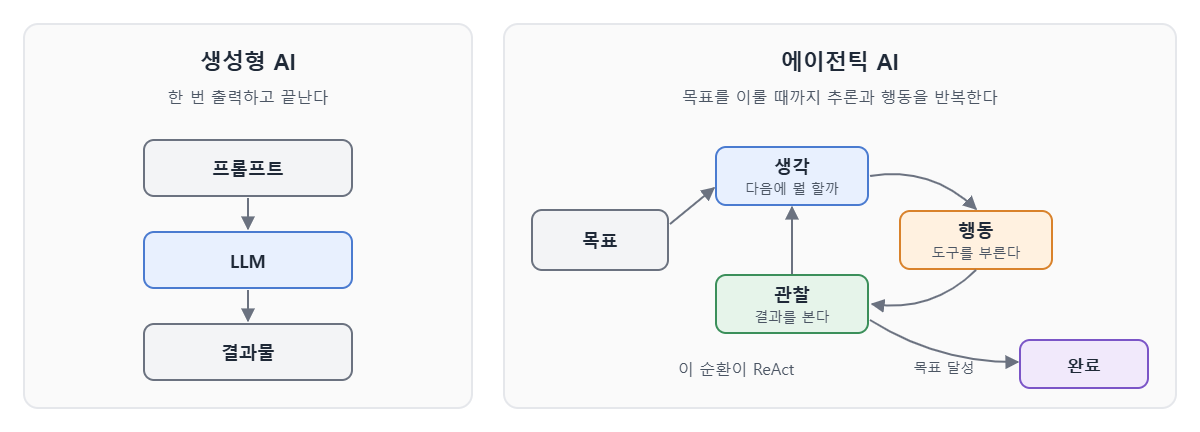<br>
프롬프트에 맞는 결과물을 한 번 출력하고 끝

#### 에이전틱 AI
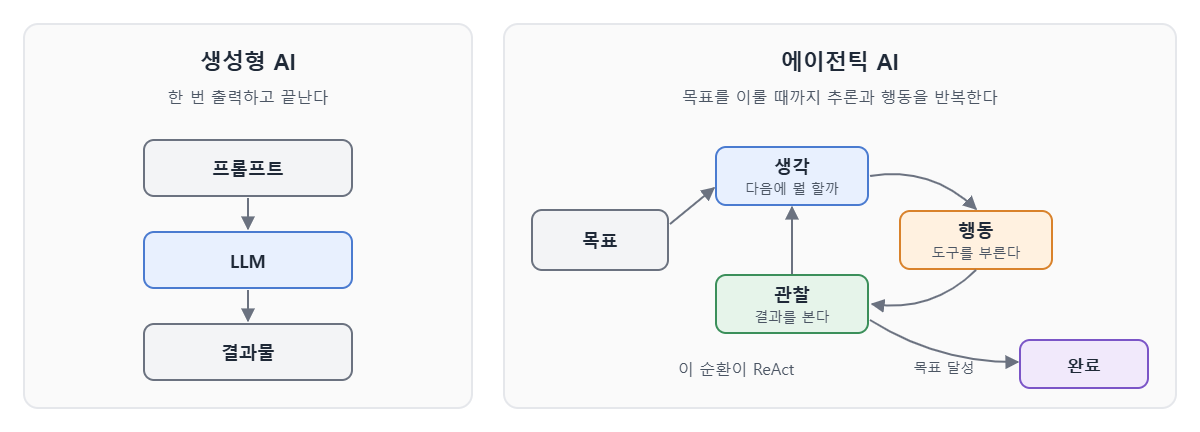<br>
목표를 달성할 때까지 추론과 행동을 반복

### ReAct (생각 → 행동 → 관찰)
생각 -> 행동 -> 관찰 -> 생각 의 순환 반복

### 다중 에이전트 : 오케스트레이터 + 서브 에이전트
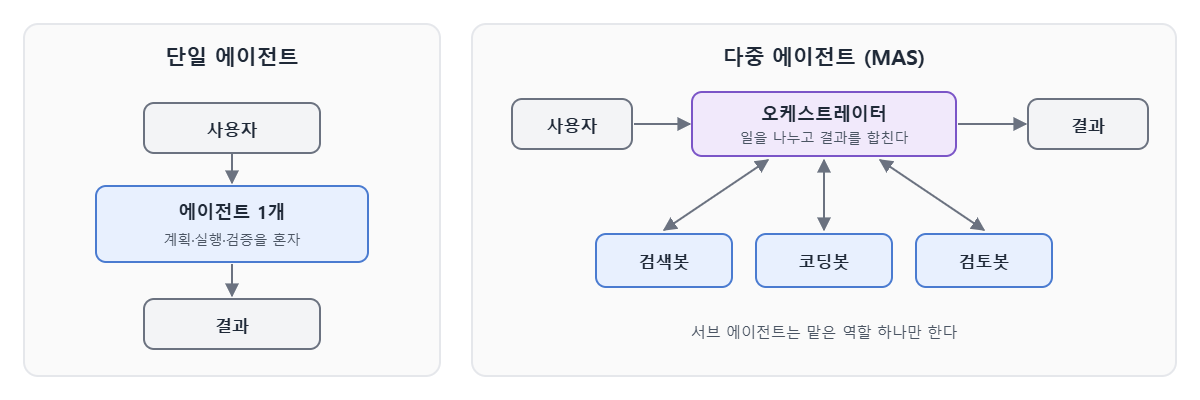<br>
#### MAS(Multi Agent System) 구조
MAS(멀티 에이전트): 여러 에이전트가 역할을 나눠 함께 일하는 구조
#### 오케스트레이터(지휘자)
요청을 작은 일로 쪼갬 -> 누구에게 맡길지 결정 -> 결과를 하나로 통합
#### 서브 에이전트(전문가)
맡은 역할만 해냄

|  | 쓰는 상황 | 예시 |
| --- | --- | --- |
| 고정 워크플로우 | 순서가 정해진 단순 작업 | 매일 아침 신규 주문 정리 → 메일 발송 |
| 단일 에이전트 | 도구 몇 개로 해결되는 작업 | 앞에서 본 배송 지연 처리 |
| 다중 에이전트 | 따로 조사해서 합칠 수 있는 큰 작업 | S&P 500 IT 기업 이사진 조사 |

## MCP란?
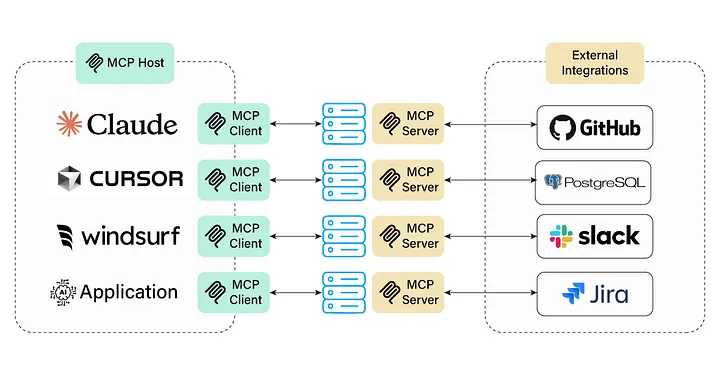<br>
LLM 앱(호스트, 클라이언트)과 외부 데이터/도구(서버)가 통신하는 개방형 표준 프로토콜

### USB-C 비유
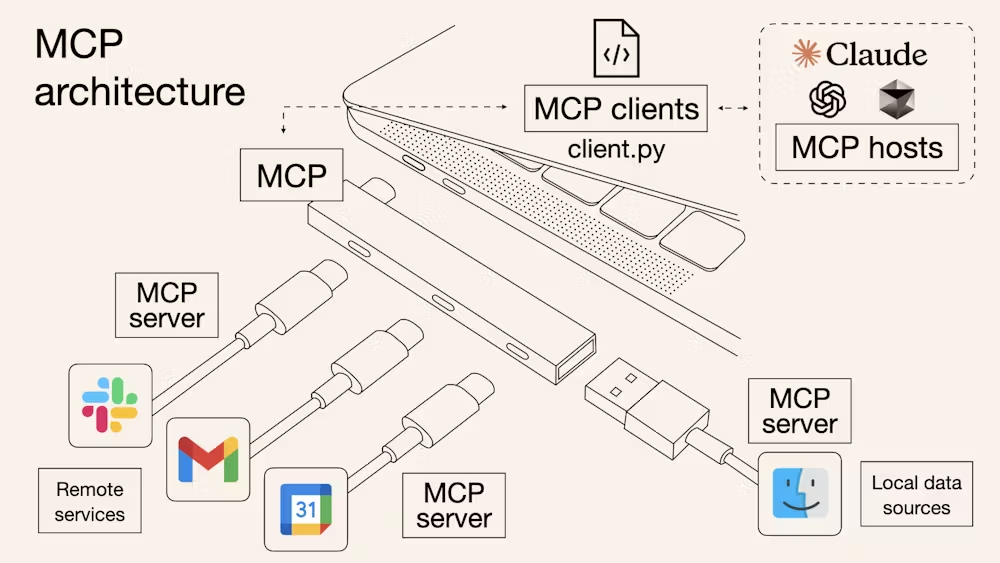<br>
- 예전: 기기마다 충전 단자가 달라 케이블을 종류별로 → 지금: USB-C 하나로 노트북·휴대폰 모두 충전
- MCP = **AI 앱과 도구 사이의 USB-C** → 어떤 앱이든 어떤 도구든 같은 단자로 연결
    ex. Claude·ChatGPT에서 노션·구글 드라이브 "연결" 버튼 → 그 밑에서 이런 규격이 작동

### 도구 호출의 원리 : Function Calling
모델이 "이 함수를 이 인자로 불러 줘"라는 구조화된 요청을 내놓는 기능 <br>
|  | Function Calling | MCP |
| --- | --- | --- |
| 위치 | 모델 API 쪽 기능 | 그 위의 연동 계층 |
| 하는 일 | 모델이 도구 호출 요청을 내놓는 방법 | 앱이 도구를 찾고·연결하고·호출하는 방법 |

### MCP가 필요한 이유 : n×m → n+m
- n x m 작업량 문제
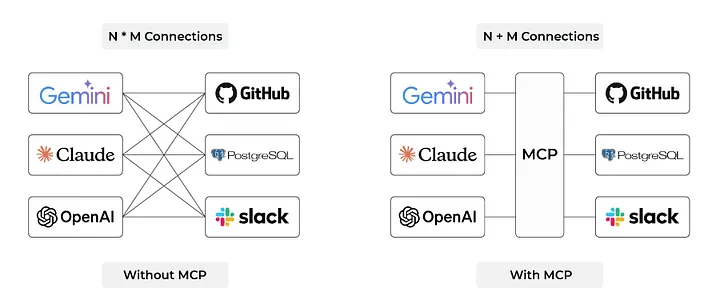 <br>
> 표준이 없을 때: 앱마다 도구마다 연동 코드를 따로 생성 -> n x m 개
> 표준이 생기면: 앱은 MCP 클라이언트 1번, 도구는 MCP 서버 1번만 -> n + m 개

### MCP의 구조 : Host / Client / Server
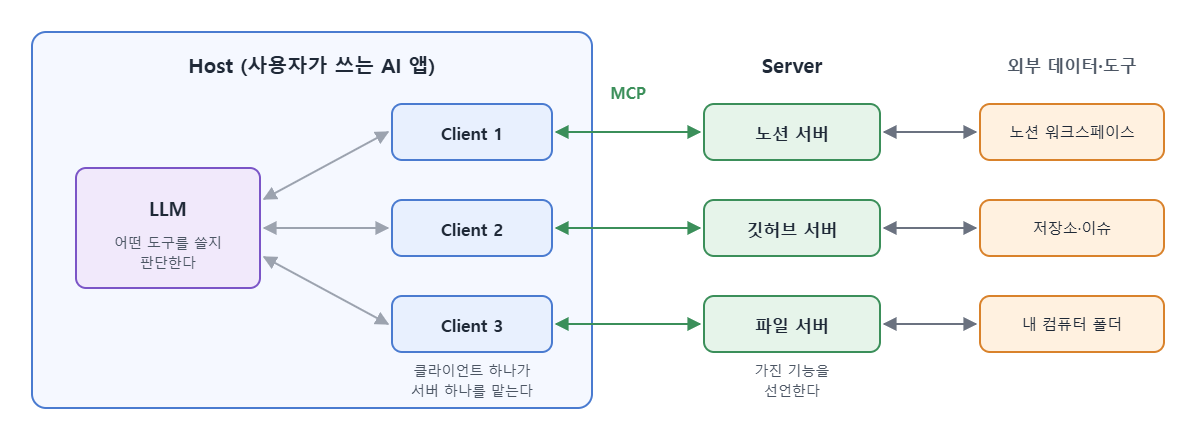<br>

| 역할 | 정체 | 하는 일 | 예시 |
| --- | --- | --- | --- |
| **Host** | 사용자가 쓰는 AI 앱 | LLM을 품고 클라이언트를 만들고 관리 / 어떤 서버·도구 호출을 허용할지 결정 | Claude, Cursor |
| **Client** | 호스트 안의 통신 담당 | 서버 1개당 1개 → MCP 규격으로 메시지 전달만 | 서버 3개 → 클라이언트 3개 |
| **Server** | 도구·데이터를 MCP 규격으로 내놓는 프로그램 | 가진 기능 선언 → 요청이 오면 실제 작업 수행 | 노션 서버, 깃허브 서버 |

### MCP 서버의 기본 요소 : Tools / Resources / Prompts
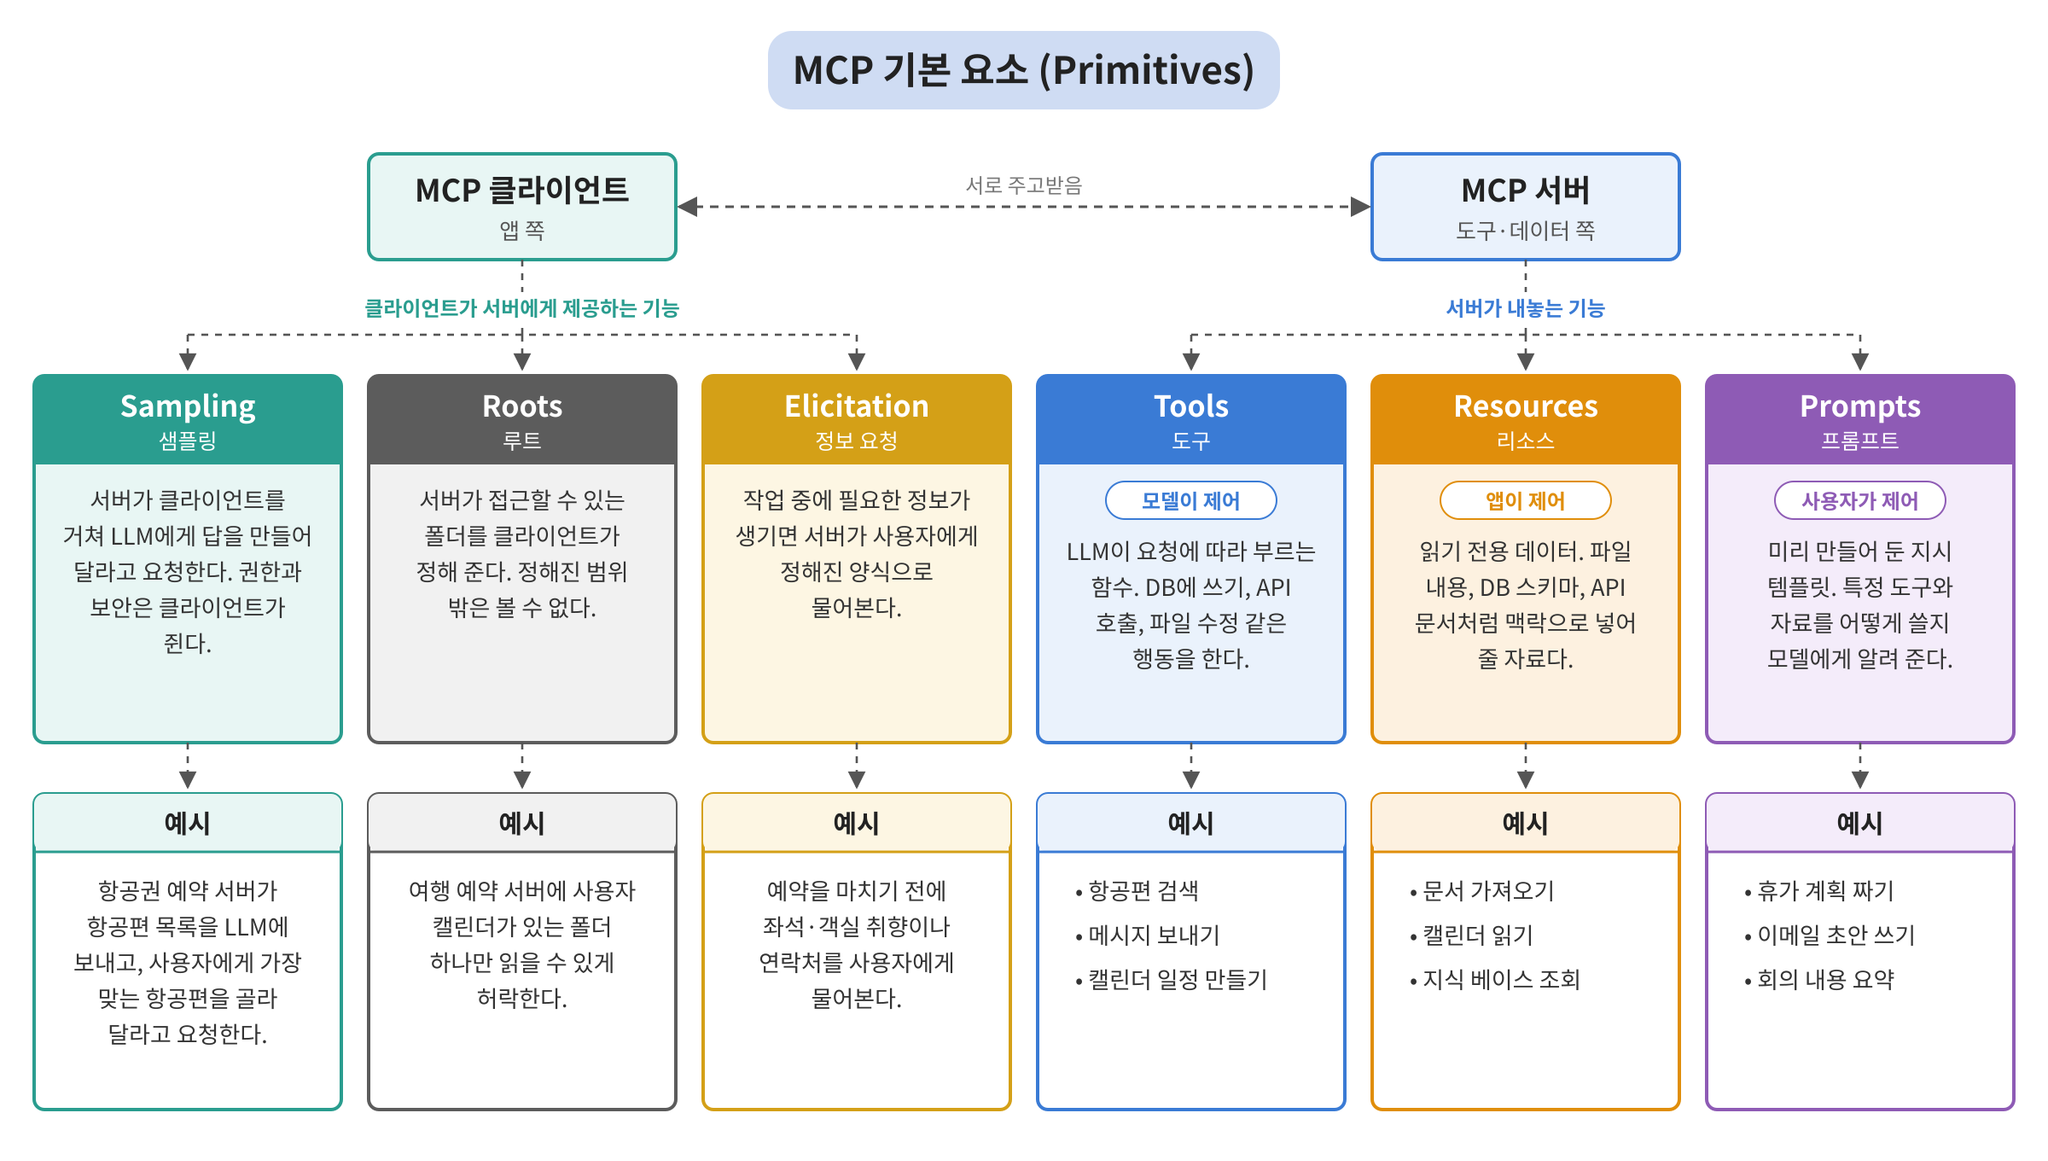 <br>
| 요소 | 무엇인가 | 예시 |
| --- | --- | --- |
| **Tools** | 실행할 수 있는 행동 | 노션 페이지 만들기, 깃허브 이슈 등록하기 |
| **Resources** | 읽기 전용 데이터 | 파일 내용, 문서, DB 스키마 |
| **Prompts** | 재사용 가능한 템플릿 | 코드 리뷰 요청 양식, 회의록 요약 양식 |

### MCP 작동 흐름
- AI가 외부 도구를 쓰는 과정
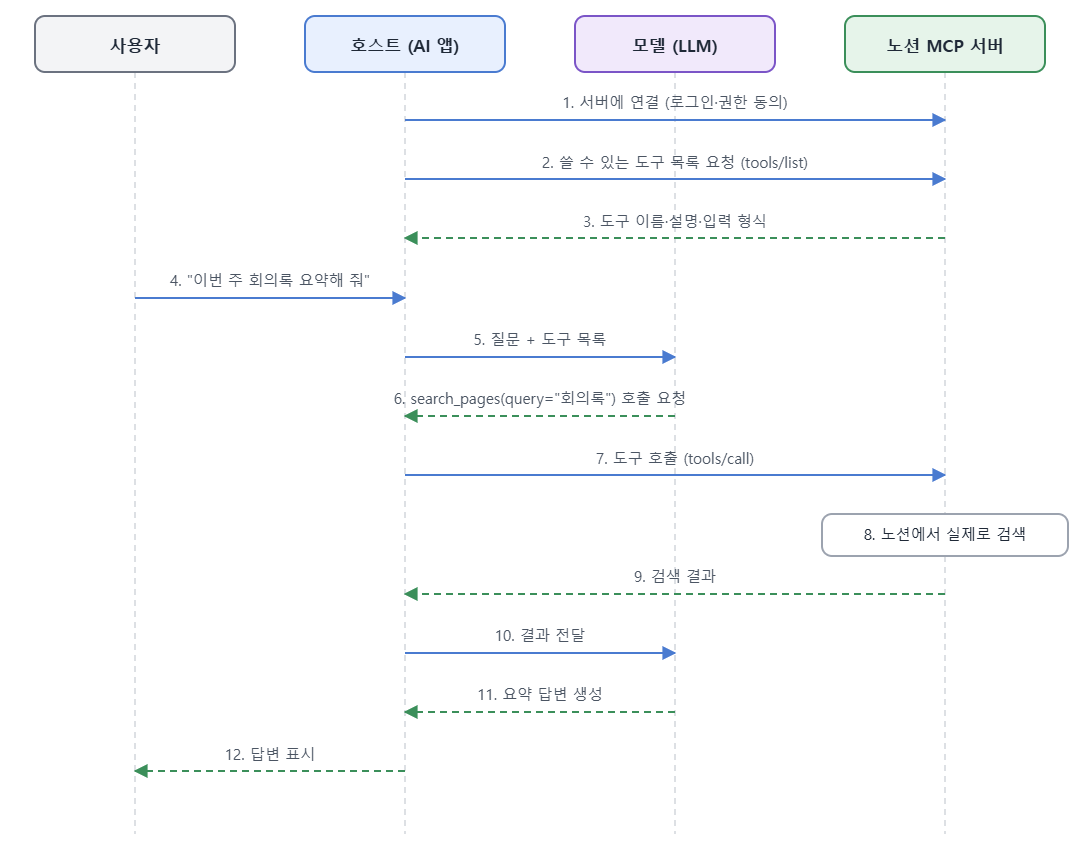 <br>

## MCP의 한계
1. 신뢰할 수 없는 서버를 붙이는 위험
- MCP 서버는 누구나 만들어 올릴 수 있음
- 프로토콜이 아니라 호스트가 보안을 책임짐.
    - 사용자 동의, 서버에 넘길 권한 범위, 허용할 도구 선택 = 모두 호스트 몫
    - MCP는 "연결하는 법"만 정함, "무엇을 허락할지"는 정하지 않음
2. 도구 설명을 통한 주입
- **도구 오염**: 도구 설명 안에 사용자에겐 안 보이고 모델에게만 보이는 지시를 숨기는 공격
3. 너무 넒은 권한 연동의 위험
- **프로므트 주입**: 도구가 가져온 내용 안에 지시가 섞여 들어오는 것

-------------------------
**안전하게 외부 도구를 쓰려면?**

- 공식적으로 검증된 서버만 연결
- 필요한 권한만 주기 (읽기만 필요하면 읽기 권한만)
- 되돌리기 어려운 호출(글 올리기·지우기)은 사람이 승인
- 처음 연결하는 서버는 도구 설명 직접 확인

## 데이터 구조화

### 왜 구조화가 필요한가
> 에이전틱 AI, 피지컬 AI가 일하려면 결국 구조화된 데이터가 필요합니다.
> 만약 사내 AI를 도입하라는 업무를 받았을 때 사내 데이터를 AI에게 전달해야하는데, 이 때 구조화가 필요

- Vanilla RAG의 한계
1. Top-K 딜레마
- **k가 작으면** → 필요한 정보를 놓침
- **k가 크면** → 관련 없는 정보가 섞임

### 그래프 구조와 팔란티어 온톨로지
- 그래프 자료구조란?
    데이터를 노드와 엣지로 표현하는 구조
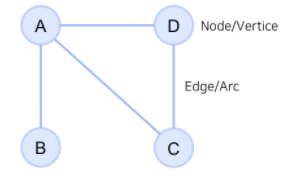<br>

---

**그래프 = 점(노드) + 선(엣지)**

- **노드** - 사물, 존재하는 것 (예: `봉준호`, `기생충`, `아카데미 작품상` )
- **엣지** - 노드 사이의 관계 (예: `봉준호—감독→ 기생충`, `기생충—수상→ 아카데이 작품상` )
---
- 팔란티어 온톨로지란?
팔란티어는 이 그래프 구조를 기업 전체에 적용하여, 흩어진 사내 데이터 (ERP, CRM, 센서 기록, 문서 등)를 하나의 의미 있는 관계망으로 묶은 것

- 온톨리지 구성요소
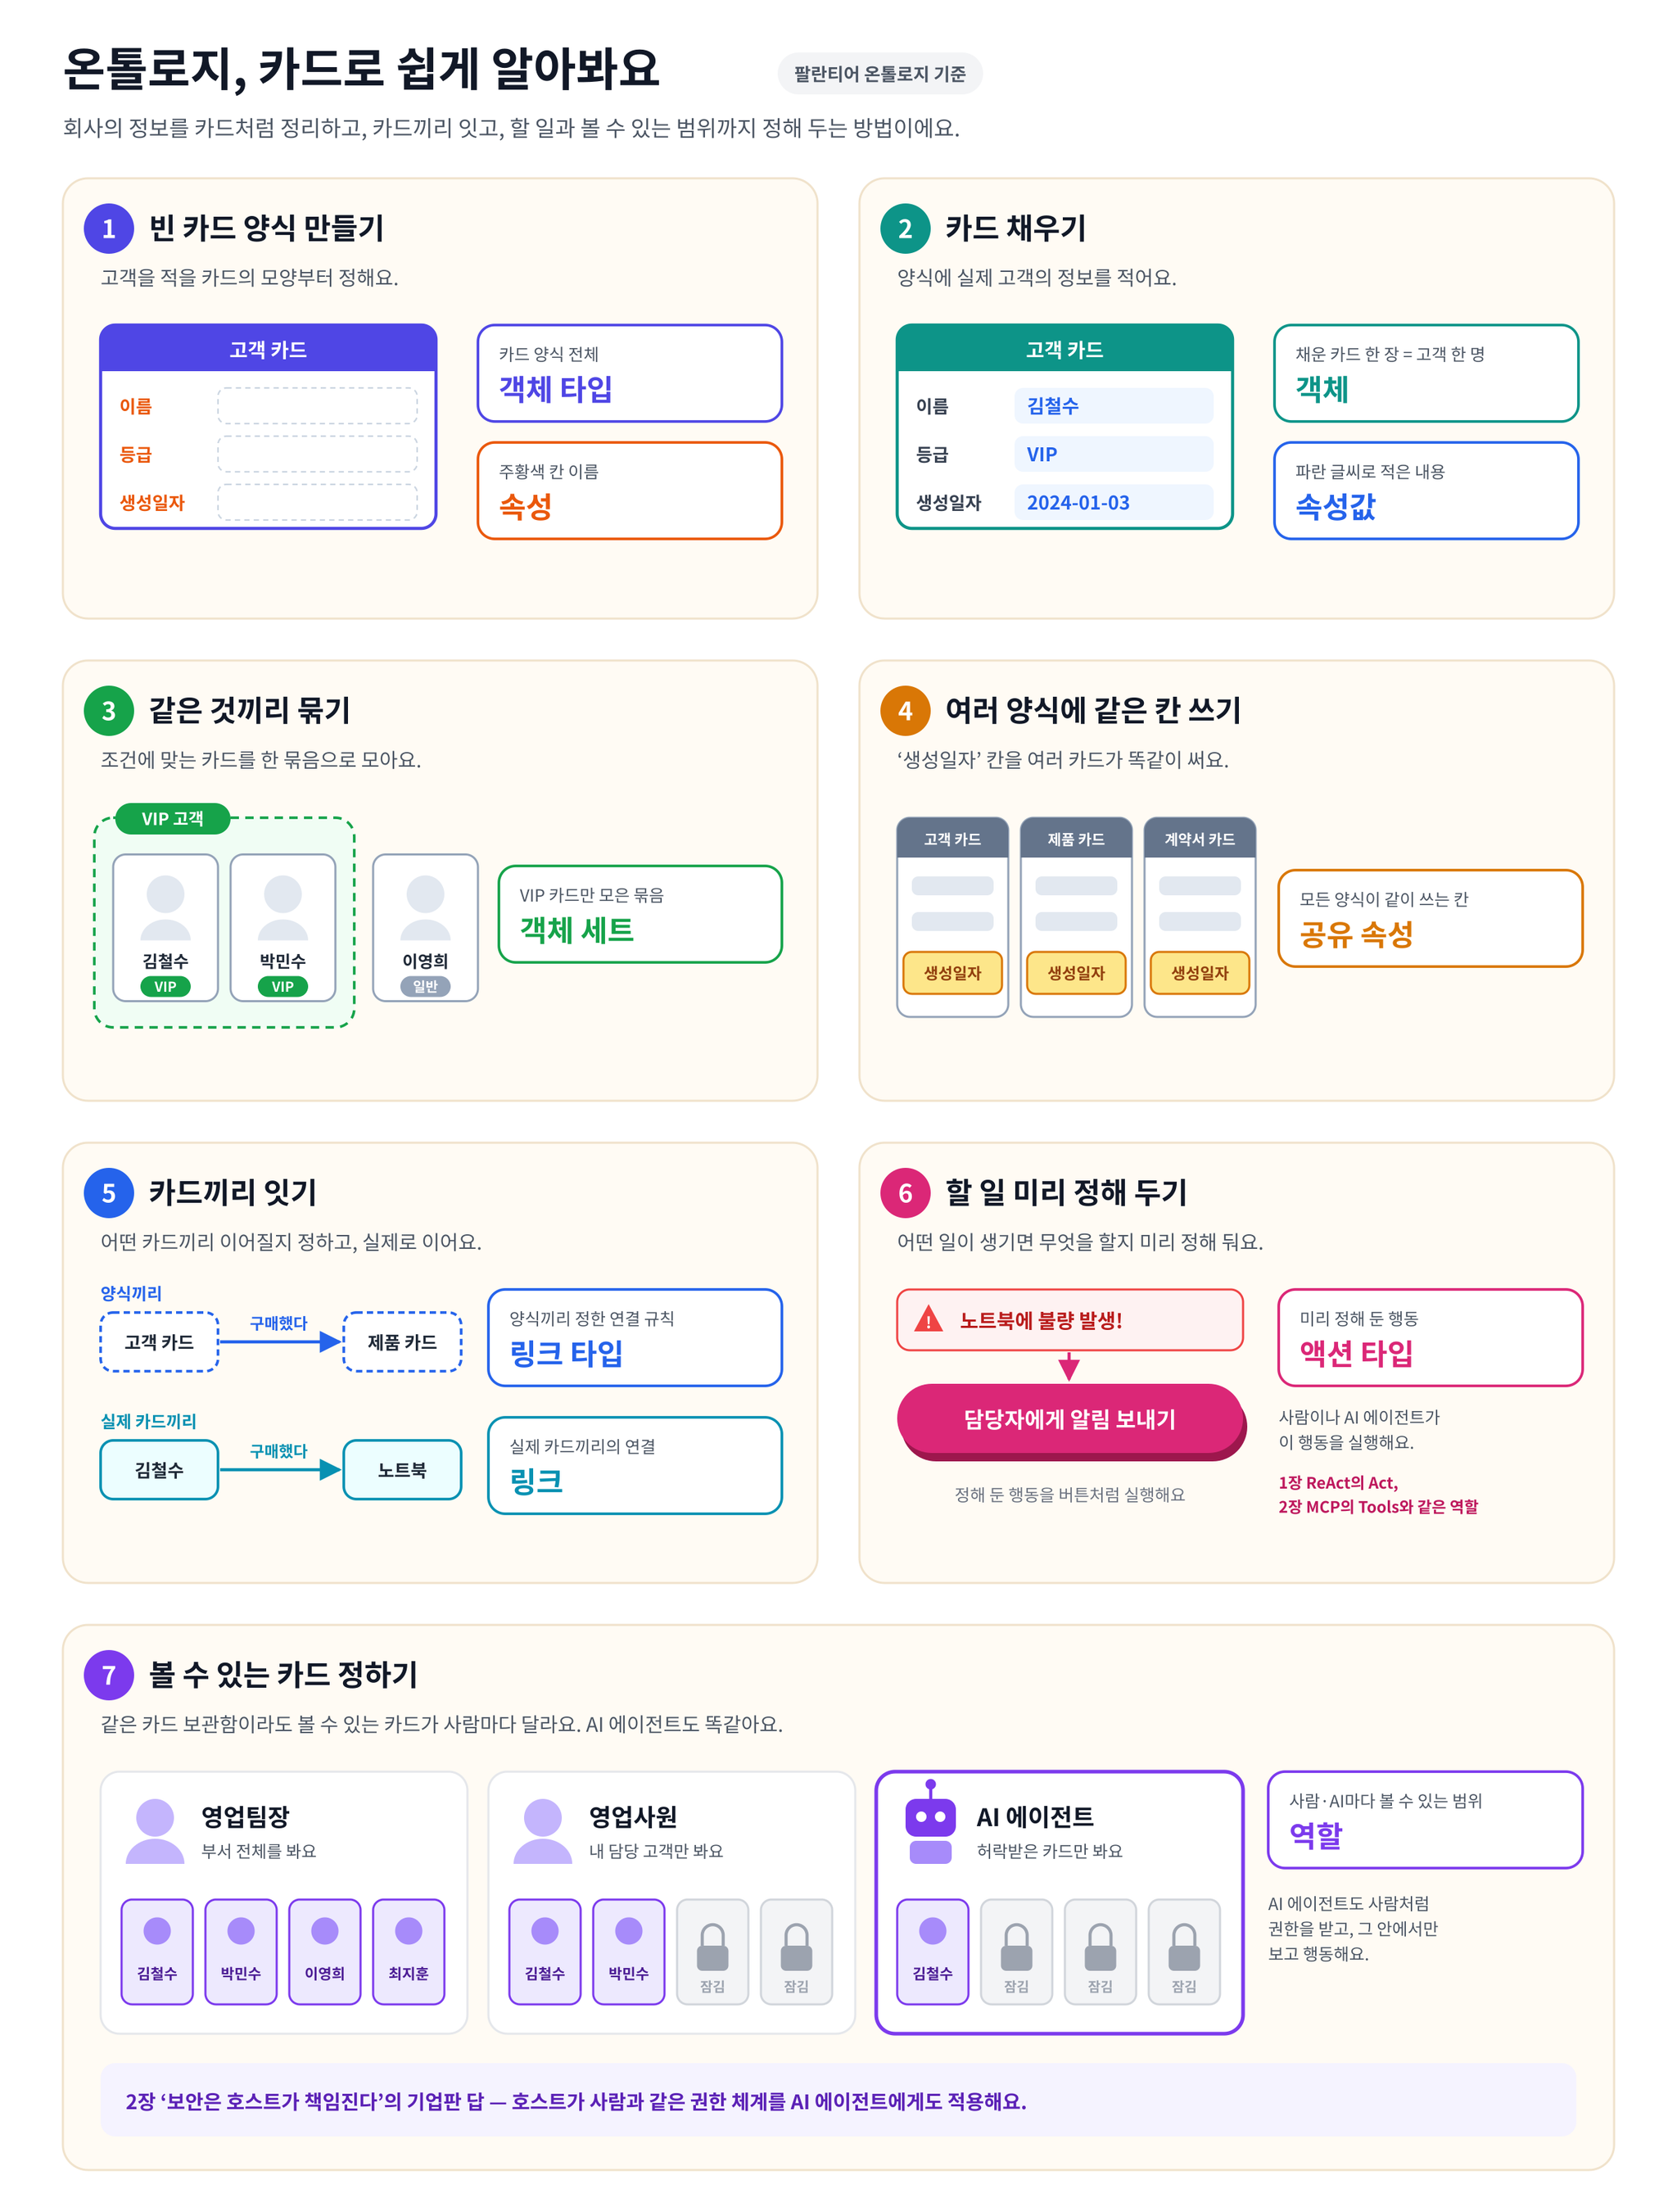 <br>
#### **객체 타입 / 객체 / 객체 세트**

**객체 타입 -** 테이블의 스키마와 같다

- 예: 고객 시트 그 자체. "고객이란 이름, 등급, 생성일자를 가진 것"이라는 틀

**객체 -** 테이블의 한 행과 같다

- 예: 고객A, 제품B 같은 실제 인스턴스

**객체 세트 -** 여러 객체의 모음

- 예: VIP 고객 전체

---

#### **속성 / 속성값**

**속성 -** 테이블의 열과 같다. 즉, 객체가 가진 특징

- 예: 이름, 날짜, 금액

**속성값 -** `김철수`, `VIP`, `2024-01-03` 같이 특정 객체가 가지는 속성의 실제 값

#### **공유 속성**

여러 객체 타입에서 공통으로 쓰는 속성

- 예: "생성일자" 속성을 고객, 제품, 계약서 모두에서 일관되게 관리할 수 있다

---

#### **링크 타입 / 링크**

**링크 타입:** 관계의 스키마

- 예: "구매했다", "담당한다"

**링크:** 실제 관계의 인스턴스

- 예: "고객A가 제품B를 구매했다"

---

#### **액션 타입 -** 일반 DB와의 가장 큰 차이점!

- 데이터를 읽는 것을 넘어, **실제 변경과 행동까지 온톨로지 위에서 정의**하는 것
    - 예: "불량 발생 시 담당자에게 알림 발송" 같은 행동이 온톨로지의 일부가 될 수 있다
        
---

#### **역할 (Roles)**

- 직급, 부서, 지역에 따라 접근 권한을 객체 단위까지 세밀하게 제어할 수 있음
- **AI 에이전트도 사람처럼 권한을 부여받음** → 부여받은 범위 안의 데이터만 조회·실행 가능

---
#### 데이터 구조 비교
| 관계형 DB (테이블) | 그래프 DB | 팔란티어 온톨로지 |
| --- | --- | --- |
| 테이블 스키마 | - | 객체 타입 |
| 행 (Row) | 노드 | 객체 |
| 열 (Column) | - | 속성 |
| 필드 값 | - | 속성값 |
| 조인 (Join) | 엣지 | 링크 타입 |
| - | - | **액션 타입** ← 온톨로지만의 차별점 |

## XAI
### 들어가기 전에
기존 AI 모델이 답하지 못하는 문제
<예시> <br>
AI 모델은 이제 사람보다 정확하게 암을 발견하고, 대출 심사를 하고, 채용 합격 여부를 가릅니다.
그러나, AI가 여전히 답을 못하는 질문이 있습니다.

> **“왜 그 결정을 내렸나요?”**

<aside>

예를 들어, 정확도 99%짜리 피부암 진단 AI가 있다고 가정해 봅시다. 

연구자들이 AI가 왜 특정 사진을 암으로 판정하는지 들여다봤더니, **사진 속에 반창고가 붙어 있으면 암으로 분류**하는 경향이 있었습니다. 

반창고가 붙은 피부 사진은 대부분 이미 의사가 살펴본 병변 사진이었기 때문에, AI가 반창고 자체를 암의 신호로 학습해버린 것입니다.

→ 이는 입력(사진)과 출력(암/정상)만 보면 절대 발견할 수 없는 문제입니다!

</aside>

**→ 그래서 등장하게 된 것이 설명 가능한 인공지능(Explainable AI, XAI)**

### 블랙박스가 왜 문제인가
딥러닝 모델은 수백만~수십억 개의 숫자(파라미터)가 복잡하게 얽혀 있어서, 사람이 직접 읽을 수 없음. 입력을 넣으면 출력이 나오지만 그 사이 과정은 사실상 블랙박스.

### 기존 해결 시도들
1. 회귀 분석 - 완전한 화이트박스
- 가장 고전적인 방법
- 결과 = a × 나이 + b × 소득 + c × 신용점수 + … 처럼 계수를 직접 읽을 수 있다.

> “나이가 1 늘면 대출 거절 확률이 2% 오른다” → 완벽한 설명!
> 
- **한계:** 세상은 그렇게 단순하지 않다. 이미지, 텍스트, 복잡한 패턴에서는 선형 모델로 충분한 정확도를 낼 수 없다. 설명은 완벽한데 성능이 너무 낮다.

2. SHAP / LIME - 사후적 설명
- 딥러닝 모델은 그대로 놔두고, 외부에서 “어떤 입력 특성이 이 결과에 얼마나 기여했는지”를 근사 계산해서 보여주는 방법
- 예를 들어 대출 거절 결과에 대해 SHAP을 쓰면 이런 출력이 나온다:
    
    `거절 이유 기여도:
      - 연체 이력:   +34%  (거절 방향)
      - 소득 수준:   -18%  (승인 방향)
      - 부채 비율:   +27%  (거절 방향)`
    
- **한계:** 모델이 실제로 하는 연산을 설명하는 게 아니라, 입력을 조금씩 바꿔보며 **역으로 추정**하는 방법이므로, “진짜 이유”가 아니라 “그렇게 보이는 것”일 수 있다. 즉, 모델이 실제로 연체 이력을 보고 결정한 건지, 아니면 연체 이력과 연관된 다른 무언가(예: 우편번호)를 보고 결정한 건지 알 수 없다.

3. LLM + RAG - 블랙박스로 블랙박스 설명하기
- “이유를 GPT한테 물어보자”는 접근
- 모델의 출력과 입력 데이터를 GPT에게 넘기고 "왜 이런 결정을 내렸을까요?"라고 묻는 방식
- **한계:** GPT 자체도 블랙박스이므로, **블랙박스가 블랙박스를 설명하는 셈**이 된다. GPT가 그럴듯한 설명을 생성해줄 수는 있지만, 그게 딥러닝 모델의 실제 내부 연산과 일치한다는 보장이 없다.

| 방법 | 설명 가능성 | 성능 | 신뢰도 |
| --- | --- | --- | --- |
| 회귀 분석 | ✅ 완전한 화이트박스 | ❌ 낮음 | ✅ 높음 |
| SHAP / LIME | 🔶 근사 설명 | ✅ 모델 성능 유지 | 🔶 부분적 |
| LLM + RAG | 🔶 생성된 설명 | ✅ 모델 성능 유지 | ❌ 낮음 |

### Mechanistic Interpretability
“**블랙박스 자체를 열어버리면 어떨까?”**

> 모델이 *무엇을* 출력하는가가 아니라, 모델이 *어떻게* 그 답에 도달하는가를 이해하자.
> 

딥러닝 모델의 내부, 즉 가중치, 뉴런, 어텐션 헤드를 직접 분석해서, 특정 기능이 모델 안 어디에 어떻게 구현되어 있는지 **회로(circuit) 수준까지 역공학(reverse engineering)** 하는 연구 분야

- 일반 XAI vs Mechanistic Interpretability
|  | 일반 XAI (SHAP, LIME 등) | Mechanistic Interpretability |
| --- | --- | --- |
| 접근 방식 | 외부에서 관찰 | 내부를 직접 해부 |
| 핵심 질문 | "이 입력이 결과에 중요했나?" | "이 뉴런이 어떤 연산을 수행하나?" |
| 분석 수준 | 입력-출력 관계 | 가중치·회로 수준 |
| 성격 | 사후적(post-hoc) | 구조적(mechanistic) |
| 비유 | 외부에서 집 창문으로 들여다보기 | 집 구조도를 직접 그리기 |
- 핵심 기법: Activation Patching
Mech. Int.에서 자주 쓰는 실험 방법으로, **"모델 내부의 어느 위치가 답을 결정하는지"**를 찾는 방법입니다.

**① 입력 두 개를 준비합니다**

|  | 입력 | 모델의 답 |
| --- | --- | --- |
| A (기준) | "프랑스의 수도는" | 파리 |
| B (비교) | "독일의 수도는" | 베를린 |

**② B를 처리하는 도중, 특정 위치의 값을 A의 값으로 바꿔 끼웁니다**

```
입력 B 처리 중  ──▶  [레이어 1] ──▶ [레이어 2] ──▶ [레이어 3] ──▶  출력
                                        ▲
                         입력 A를 처리할 때 나온 활성값으로 교체
```

**③ 출력이 어떻게 바뀌는지 봅니다**

- 출력이 "베를린" → "파리"로 바뀌면
→ 그 위치가 **"어느 나라에 대한 질문인지"를 답까지 전달하는 핵심 경로**입니다.
- 출력이 **바뀌지 않으면**
→ 그 위치 **하나만으로는** 답을 결정하지 않습니다.

### 핵심 개념 3가지
1. 모델 안에는 무엇이 있는가?
**Feature란?**

모델이 입력에서 알아챈 **개념**입니다. 특정 단어일 수도 있고, 언어·말투·상황처럼 더 추상적인 것일 수도 있음.

**Feature는 어디에 저장될까?**

| 저장 위치 | 설명 | 비유 |
| --- | --- | --- |
| 개별 뉴런 | 개념 하나가 뉴런 하나에 담김 | 빨강 = R 다이얼 하나 |
| 방향 벡터 | 개념 하나가 여러 뉴런의 조합에 담김 | 주황 = R 많이 + G 조금 |

입력에 그 개념이 등장하면 → 해당 뉴런(또는 뉴런 조합)이 **켜짐** (활성값이 커짐).

2. 그것들이 어떻게 연결되어 일하는가?
개별 뉴런을 넘어, 여러 뉴런/어텐션 헤드가 연결되어 특정 기능을 수행하는 서브네트워크를 회로라고 부름.

3. 그런데 왜 해석하기 어렵나?
> **하나의 뉴런이 여러 개념을 중첩(superposition)해서 저장한다.**


1. 모델은 개념(특징)을 뉴런 하나가 아니라 **활성 공간 안의 방향**으로 표현
2. 만약 공간이 2차원이면 서로 전혀 겹치지 않는 (직교하는) 방향은 2개 밖에 없음. 특징이 2개면 깔끔하게 하나씩 배정할 수 있음.
3. 그런데 표현해야 할 특징이 5개라면, 모델은 5개 방향을 **조금씩 겹치게 배치**
4. 겹치니까 한 특징을 읽을 때 다른 특징이 조금 섞여 들어오는데, 이를 **간섭(interference)** 라고 함.
5. 모델이 간섭을 감수하는 이유는 **특징이 드물게(sparse) 나타나기** 때문. 5개가 동시에 켜지는 일은 거의 없어서, 대부분의 경우 간섭이 문제를 일으키지 않아요. 그래서 손해보다 더 많은 특징을 담는 이득이 큼.
6. 그리고 이 특징 방향들이 뉴런 축(좌표축)과 맞지 않으니, **뉴런 하나를 보면 여러 특징이 조금씩 걸쳐 보이게 됩니다.**
→ 앞에서 말한 다의성이 생기는 이유!

이게 Mech. Int. 연구를 어렵게 만드는 가장 큰 원인입니다. "뉴런 하나 = 개념 하나"가 아니기 때문에, 뉴런을 읽어도 무슨 개념인지 바로 알 수 없음 <br>

> 이를 해결하려고 나온 도구가 **Sparse Autoencoder(SAE)** 중첩된 개념들을 수학적으로 분리해서 각 개념을 독립적으로 추출하는 방법